### Homework 05 - Volume estimate using Monte Carlo method
Igor Di Tota

**Introduction**

In this exercise, the Monte Carlo method is used to compute the volume of a solid defined as the intersection of three cones placed inside the unit cube $[0,1]^3$.

Each cone has unit height and unit base diameter.
The axes of the three cones are mutually perpendicular.

The solid considered is the set of points belonging to all three cones at the same time.
The volume is estimated by generating random points uniformly inside the cube and counting the fraction that falls inside the solid.

The work is organised as follows:
- definition of the geometry and of the conditions for a point to be inside each cone;
- validation of the method on a single cone;
- estimate of the volume of the intersection and of its statistical uncertainty;
- study of the convergence of the estimate as a function of the number of generated points.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("images", exist_ok=True)

rng = np.random.default_rng(23)

### Geometry of the problem

A Cartesian reference frame is chosen with the cube occupying the region $[0,1]^3$.
For a cone with axis along the coordinate $x_k$ ($k = 0, 1, 2$ for $x, y, z$), the base of radius $R = 1/2$ lies on a face of the cube and the apex at the centre of the opposite face, at distance $H = 1$ from the base.
For the cones along $x$ and $z$ the base lies on the face $x_k = 0$ and the apex on the face $x_k = 1$, while for the cone along $y$ the base lies on the face $y = 1$ and the apex on the face $y = 0$.

Let $t = x_k$ be the coordinate along the axis and $(u, v)$ the two remaining coordinates.
At height $t$, the cross-section of the cone is a disc centred on the axis, $(u, v) = (1/2, 1/2)$, whose radius decreases linearly from $R$ at the base to $0$ at the apex:
$$
r(t) = R \left(1 - \frac{t}{H}\right).
$$
A point $(x, y, z)$ is therefore inside the cone if its distance from the axis does not exceed $r(t)$:
$$
\left(u - \tfrac{1}{2}\right)^2 + \left(v - \tfrac{1}{2}\right)^2 \le R^2 \left(1 - \frac{t}{H}\right)^2 .
$$

Explicitly, for the three cones:
$$
\begin{aligned}
\text{cone } x: &\quad (y - \tfrac12)^2 + (z - \tfrac12)^2 \le \tfrac14 (1 - x)^2, \\
\text{cone } y: &\quad (z - \tfrac12)^2 + (x - \tfrac12)^2 \le \tfrac14 (1 - y)^2, \\
\text{cone } z: &\quad (x - \tfrac12)^2 + (y - \tfrac12)^2 \le \tfrac14 (1 - z)^2 .
\end{aligned}
$$
The solid is the set of points satisfying all three conditions at the same time.

### Implementation

The functions below are written for a cone with a generic axis $x_k$, where $k = 0, 1, 2$ stands for $x, y, z$.
In this way, the same code can be reused for all three cones by changing the index $k$.
The two coordinates perpendicular to the axis are obtained cyclically as $x_{(k+1) \bmod 3}$ and $x_{(k+2) \bmod 3}$.

The function `inside` takes an array of points of shape $(3, N)$ and applies the condition derived above, returning a boolean mask that is `True` for the points inside the cone.
The intersection of the three cones is then simply the logical AND of the three masks.
The option `flip` moves the base to the opposite face, replacing $t \to 1 - t$.

The lateral surface of the cone is described in parametric form, with the coordinate along the axis $t$ and the azimuthal angle $\varphi$ around the axis:
$$
t \in [0, H], \quad \varphi \in [0, 2\pi]: \qquad
x_k = t, \quad
u = \tfrac12 + r(t)\cos\varphi, \quad
v = \tfrac12 + r(t)\sin\varphi ,
$$
with $r(t) = R\,(1 - t/H)$.
On a grid of values of $(t, \varphi)$, the three coordinates are computed and placed in the correct order according to the direction of the axis.
The function `plot_cube` draws the twelve edges of the cube: for each direction there are four edges, going from $0$ to $1$ along that coordinate, with the other two coordinates fixed to $0$ or $1$.


In [2]:
# Cone dimensions
R = 0.5
H = 1.0

def inside(points, axis, flip=False):
    "Mask of the points inside the cone with axis along coordinate `axis`"
    t = points[axis]
    if flip:
        t = 1 - t
    u = points[(axis + 1) % 3]
    v = points[(axis + 2) % 3]
    r2 = (u - 0.5)**2 + (v - 0.5)**2
    return r2 <= (R * (1 - t / H))**2


def plot_cone(ax, axis, flip=False, color="tab:red", alpha=0.4, n_phi=200):
    "Draws the lateral surface of the cone with axis along coordinate `axis`."
    t, phi = np.meshgrid(np.linspace(0, H, 2), np.linspace(0, 2 * np.pi, n_phi))
    r = R * (1 - t / H)
    coords = np.empty((3,) + t.shape)
    if flip:
        coords[axis] = 1 - t
    else:
        coords[axis] = t
    coords[(axis + 1) % 3] = 0.5 + r * np.cos(phi)
    coords[(axis + 2) % 3] = 0.5 + r * np.sin(phi)
    ax.plot_surface(*coords, color=color, alpha=alpha, rstride=1, cstride=1,
                    linewidth=0, antialiased=True, shade=True)



def plot_cube(ax, color="silver", linewidth=0.6):
    """Draws the 12 edges of the unit cube."""
    for a in [0, 1]:
        for b in [0, 1]:
            ax.plot([0, 1], [a, a], [b, b], color=color, linewidth=linewidth)   # edges along x
            ax.plot([a, a], [0, 1], [b, b], color=color, linewidth=linewidth)   # edges along y
            ax.plot([a, a], [b, b], [0, 1], color=color, linewidth=linewidth)   # edges along z


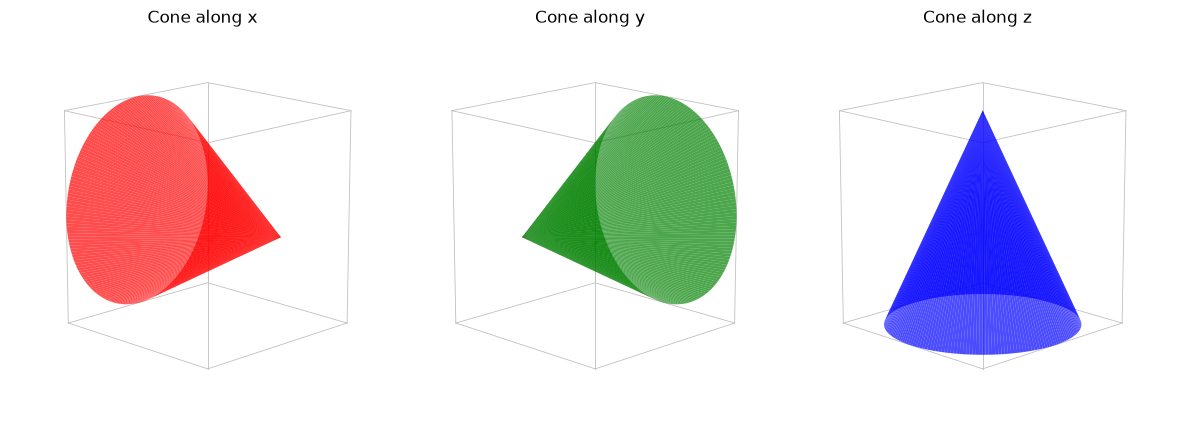

In [3]:
cones = [(0, "red", False), (1, "green", True), (2, "blue", False)]
alp = 0.7
axis_names = ["x", "y", "z"]

fig = plt.figure(figsize=(15, 5))
for k, (axis, color, flip) in enumerate(cones):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    plot_cube(ax)
    plot_cone(ax, axis, color=color, flip=flip, alpha=alp)

    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.view_init(elev=15, azim=-45)
    ax.set_title(f"Cone along {axis_names[axis]}")

fig.subplots_adjust(wspace=0)
fig.savefig("images/single_cones.pdf", bbox_inches="tight")
plt.show()


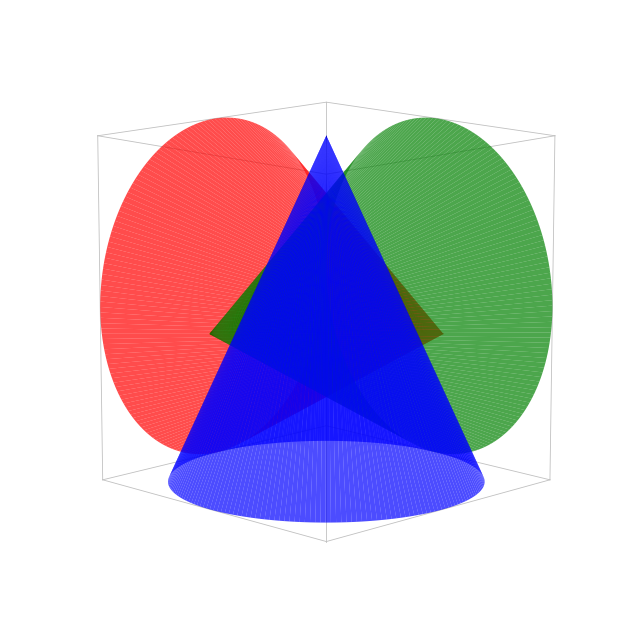

In [4]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
plot_cube(ax)
for axis, color, flip in cones:
    plot_cone(ax, axis, color=color, flip=flip, alpha=alp)

ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.view_init(elev=12, azim=-45)
fig.savefig("images/cones.pdf", bbox_inches="tight")
plt.show()


normalised residual### Monte Carlo integration

The volume is estimated with the *hit-or-miss* method seen in the lecture.
$N$ points are generated uniformly inside the unit cube, drawing each coordinate independently from the uniform distribution on $[0, 1[$.
For each point it is checked whether it lies inside the solid, and the number of accepted points $N_f$ is counted.

Since the points are uniformly distributed, the probability for a point to be accepted is the ratio between the volume of the solid and the volume $I_0$ of the region where the points are generated:
$$
p = \lim_{N \to \infty} \frac{N_f}{N} = \frac{V}{I_0}.
$$
Here the points are generated in the whole cube, so $I_0 = V_{\text{cube}} = 1$.
The volume is then estimated as
$$
V = \frac{N_f}{N} \, I_0 = \hat{p} \, I_0 .
$$

Each point is accepted or rejected independently with the same probability $p$, so $N_f$ follows a binomial distribution with variance $N p (1 - p)$.

For $N \gg 1$, the uncertainty on the volume is therefore
$$
\sigma_V = \sqrt{\frac{\hat{p}(1 - \hat{p})}{N}} \; I_0 .
$$
The uncertainty decreases as $1/\sqrt{N}$, independently of the number of dimensions of the problem.

#### Validation on a single cone

Before computing the volume of the solid, the method is checked on a single cone, whose volume is known exactly:
$$
V_{\text{cone}} = \frac{1}{3} \pi R^2 H = \frac{\pi}{12} \approx 0.2618 .
$$
The check is done on the cone with axis along $z$: the difference from the exact value is compared with the statistical uncertainty through the normalised residual $(V_{\text{MC}} - V_{\text{exact}})/\sigma_V$, which should be of order 1 if the method and its uncertainty are correct.


In [5]:
def mc_volume(mask, I0 = 1.0):
    N = mask.size
    p = mask.sum() / N
    V = p * I0
    sigma_V = np.sqrt(p * (1 - p) / N) * I0
    return V, sigma_V


N = 1000000
points = rng.random((3, N))

V_exact = np.pi * R**2 * H / 3

# Cone along z
V, sigma_V = mc_volume(inside(points, axis=2))
resnorm = (V - V_exact) / sigma_V

print(f"Exact volume:     {V_exact:.5f}")
print(f"Monte Carlo:      {V:.5f} ± {sigma_V:.5f}")
print(f"Difference:       {V - V_exact:.5f}")
print(f"Residual norm:    {resnorm:.2f}")


Exact volume:     0.26180
Monte Carlo:      0.26243 ± 0.00044
Difference:       0.00063
Residual norm:    1.44


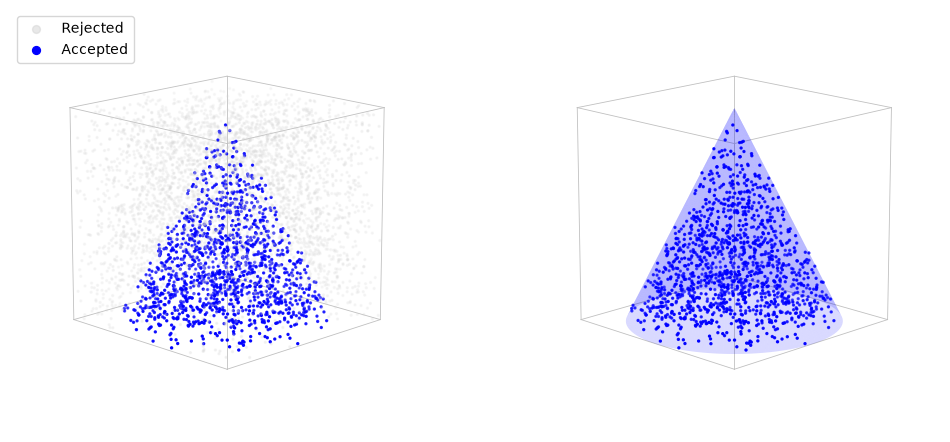

Accepted points shown: 1382/5000  (fraction 0.276)


In [6]:
n_show = 5000

mask_z = inside(points, axis=2)
pts = points[:, :n_show]
acc = mask_z[:n_show]

fig = plt.figure(figsize=(12, 6))

# All points: accepted and rejected
ax = fig.add_subplot(1, 2, 1, projection="3d")
plot_cube(ax)
ax.scatter(*pts[:, ~acc], s=2, color="lightgray", alpha=0.5, label="Rejected")
ax.scatter(*pts[:, acc], s=2, color="blue", label="Accepted")
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.view_init(elev=15, azim=-45)
ax.legend(loc="upper left", markerscale=4)

# Only accepted points, together with the cone surface
ax = fig.add_subplot(1, 2, 2, projection="3d")
plot_cube(ax)
plot_cone(ax, axis=2, color="blue", alpha=0.15)
ax.scatter(*pts[:, acc], s=2, color="blue")
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.view_init(elev=15, azim=-45)

fig.savefig("images/cone_points.pdf", bbox_inches="tight")
plt.show()

print(f"Accepted points shown: {acc.sum()}/{n_show}  (fraction {acc.mean():.3f})")


### Volume of the intersection

The volume of the solid is estimated with the same procedure.
A point is accepted only if it lies inside all three cones, i.e. the acceptance mask is the logical AND of the three masks:
$$
\text{accepted} = \text{cone}_x \wedge \text{cone}_y \wedge \text{cone}_z .
$$

In [7]:
N = 10000000
points = rng.random((3, N))

mask_solid = (inside(points, axis=0) & inside(points, axis=1, flip=True) & inside(points, axis=2))

V_solid, sigma_V_solid = mc_volume(mask_solid)

print(f"Generated points:     N   = {N:e}")
print(f"Accepted points:      N_f = {mask_solid.sum():e}")
print(f"Acceptance fraction:  p   = {mask_solid.mean():.5f}\n")
print(f"Volume of the solid:  V = {V_solid:.5f} ± {sigma_V_solid:.5f}")
print(f"Relative uncertainty:     {sigma_V_solid / V_solid * 100:.3f}%")


Generated points:     N   = 1.000000e+07
Accepted points:      N_f = 6.092620e+05
Acceptance fraction:  p   = 0.06093

Volume of the solid:  V = 0.06093 ± 0.00008
Relative uncertainty:     0.124%


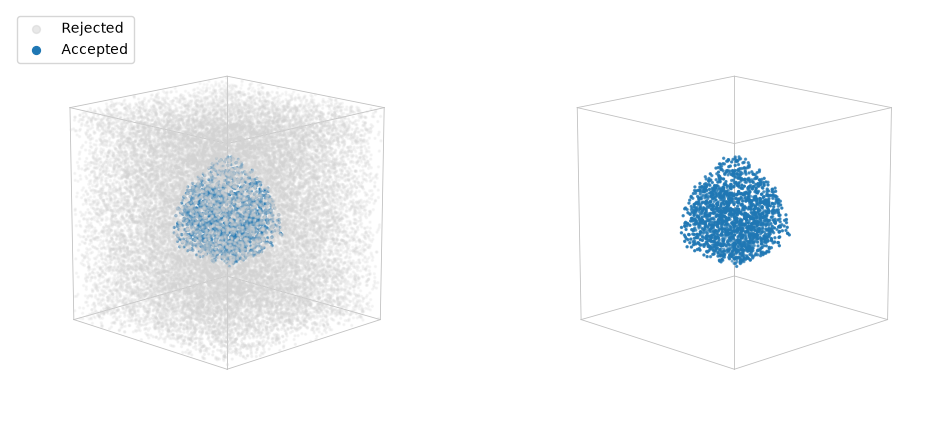

Accepted points shown: 1787/30000  (fraction 0.060)


In [8]:
n_show = 30000

pts = points[:, :n_show]
acc = mask_solid[:n_show]

fig = plt.figure(figsize=(12, 6))

# Accepted and rejected points
ax = fig.add_subplot(1, 2, 1, projection="3d")
plot_cube(ax)
ax.scatter(*pts[:, ~acc], s=2, color="lightgray", alpha=0.5, label="Rejected", rasterized=True)
ax.scatter(*pts[:, acc], s=2, color="tab:blue", label="Accepted", rasterized=True)
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.view_init(elev=15, azim=-45)
ax.legend(loc="upper left", markerscale=4)

# Accepted points
ax = fig.add_subplot(1, 2, 2, projection="3d")
plot_cube(ax)
ax.scatter(*pts[:, acc], s=2, color="tab:blue", rasterized=True)
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.view_init(elev=15, azim=-45)

fig.savefig("images/solid_points.pdf", bbox_inches="tight")
plt.show()

print(f"Accepted points shown: {acc.sum()}/{n_show}  (fraction {acc.mean():.3f})")


### Convergence study

To study how the estimate depends on the number of generated points, the volume and its uncertainty are computed using only the first $N$ points of the sample, for values of $N$ from $10^2$ to $10^7$.

For each $N$, the binomial uncertainty is
$$
\sigma_V = \sqrt{\frac{\hat{p} (1 - \hat{p})}{N}} \; I_0 ,
\qquad
\frac{\sigma_V}{V} = \sqrt{\frac{1 - \hat{p}}{N \hat{p}}} \propto \frac{1}{\sqrt{N}} .
$$
On a logarithmic scale the relative uncertainty is therefore expected to follow a straight line with slope $-1/2$.
The expected curve is obtained by using the best estimate of $p$, from the full sample of $10^7$ points.
The exact volume is not known, so the estimates are compared with this same best estimate.


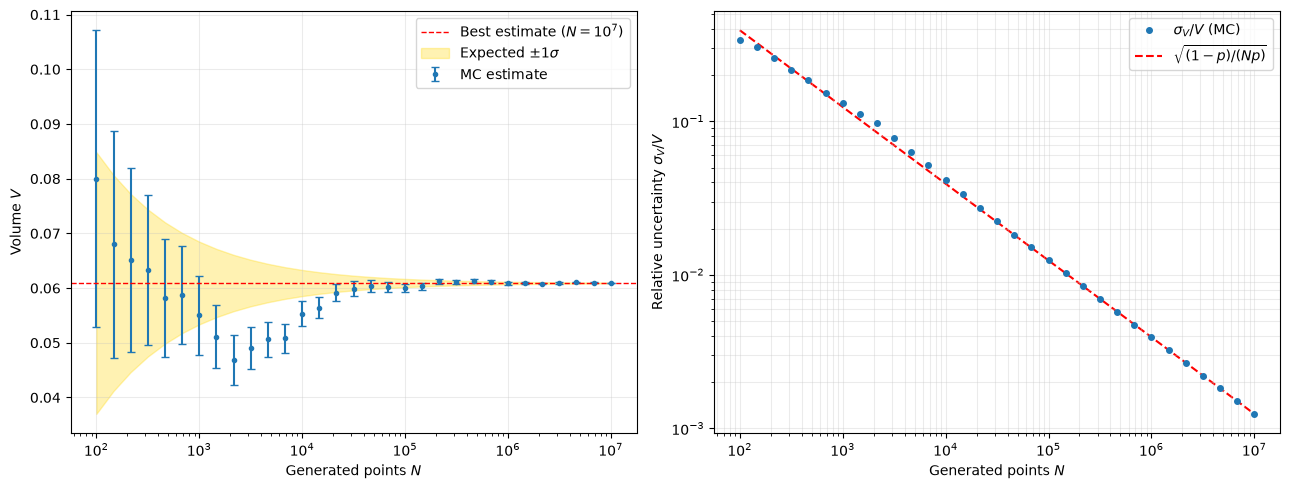

         N       N_f         V   sigma_V  rel. unc.
       100         8   0.08000   0.02713     33.91%
       681        40   0.05874   0.00901     15.34%
      4642       235   0.05062   0.00322      6.36%
     31623      1895   0.05992   0.00133      2.23%
    215443     13193   0.06124   0.00052      0.84%
   1467799     89332   0.06086   0.00020      0.32%
  10000000    609262   0.06093   0.00008      0.12%


In [9]:
N_values = np.round(np.logspace(2, 7, 31)).astype(int)

# Number of accepted points among the first N, for every N
N_f_cumulative = np.cumsum(mask_solid)
N_f = N_f_cumulative[N_values - 1]

p_N = N_f / N_values
V_N = p_N
sigma_N = np.sqrt(p_N * (1 - p_N) / N_values)

# Expected relative uncertainty, using the best estimate of p
p_best = V_solid
rel_expected = np.sqrt((1 - p_best) / (N_values * p_best))

fig, (ax_V, ax_rel) = plt.subplots(1, 2, figsize=(13, 5))

# Volume estimate as a function of N
ax_V.errorbar(N_values, V_N, yerr = sigma_N, fmt = ".", color = "tab:blue", capsize = 3, label = "MC estimate")
ax_V.axhline(V_solid, color = "red", linestyle = "--", linewidth = 1, label=fr"Best estimate ($N = 10^7$)")
ax_V.fill_between(N_values, V_solid - rel_expected * V_solid, V_solid + rel_expected * V_solid, color = "gold", alpha = 0.3, label = r"Expected $\pm 1\sigma$")
ax_V.set_xscale("log")
ax_V.set_xlabel("Generated points $N$")
ax_V.set_ylabel("Volume $V$")
ax_V.legend()
ax_V.grid(alpha = 0.3, color = "silver")

# Relative uncertainty as a function of N
ax_rel.plot(N_values, sigma_N / V_N, "o", ms = 4, color = "tab:blue", label = r"$\sigma_V / V$ (MC)")
ax_rel.plot(N_values, rel_expected, "--", color = "red", label = r"$\sqrt{(1-p)/(Np)}$", zorder=0)
ax_rel.set_xscale("log")
ax_rel.set_yscale("log")
ax_rel.set_xlabel("Generated points $N$")
ax_rel.set_ylabel("Relative uncertainty $\\sigma_V / V$")
ax_rel.legend()
ax_rel.grid(alpha = 0.3, which="both", color = "silver")

fig.tight_layout()
fig.savefig("images/convergence.pdf", bbox_inches="tight")
plt.show()

print(f"{'N':>10}{'N_f':>10}{'V':>10}{'sigma_V':>10}{'rel. unc.':>11}")
for n, nf, v, s in zip(N_values[::5], N_f[::5], V_N[::5], sigma_N[::5]):
    print(f"{n:>10}{nf:>10}{v:>10.5f}{s:>10.5f}{s / v * 100:>10.2f}%")


### Conclusions

The volume of the solid obtained as the intersection of three perpendicular cones inside the unit cube was estimated with the hit-or-miss Monte Carlo method.

The method was first validated on a single cone.
With $N = 10^6$ points the estimate $V = 0.26243 \pm 0.00044$ agrees with the exact value $\pi/12 \approx 0.26180$ within $1.4\,\sigma$.

Using $N = 10^7$ points, of which $N_f \approx 6.09 \times 10^5$ were accepted, the volume of the solid is
$$
V = 0.06093 \pm 0.00008 ,
$$
with a relative uncertainty of about $0.12\%$.

The convergence study shows that the relative uncertainty decreases as $1/\sqrt{N}$, as expected from the binomial distribution of the number of accepted points.
The estimates obtained with fewer points fluctuate around the final value, compatibly with their uncertainties.